# Commercial Fleet Route Optimization - Step 2: Classical Preprocessing
This notebook parses the SUMO network file (`osm.net.xml.gz`), builds a NetworkX directed graph restricted to roads a delivery van can use (largest strongly connected component), and computes candidate paths with Yen's $k$-shortest simple paths algorithm.

**Outputs for the QUBO step:** `paths[d]`, `C[(d,p)]` (free-flow seconds), `E[(d,p)]` (edge-ID sets), `S[(a,b)]` (shared-edge counts between routes).

In [15]:
# Install required libraries if not already installed
%pip install sumolib networkx matplotlib qiskit

Note: you may need to restart the kernel to use updated packages.


In [16]:
import os
import random
from itertools import islice, combinations

import sumolib
import networkx as nx
import matplotlib.pyplot as plt
import math

## 1. Build the road graph
Only vehicle-accessible edges are kept (`allows("delivery")`), zero-speed edges are skipped, parallel edges keep the faster one, and the graph is reduced to its largest strongly connected component so every depot→destination path exists.

In [17]:
net_path = os.path.join(os.curdir, "SUMO_GEN_SCENARIO", "osm.net.xml.gz")
assert os.path.exists(net_path), f"File not found: {net_path}"
print(f"Found network file at: {net_path}")

net = sumolib.net.readNet(net_path)

G = nx.DiGraph()
for edge in net.getEdges():
    # Skip internal junction connectors and roads a delivery van cannot drive on
    if edge.isSpecial() or not edge.allows("delivery"):
        continue
    speed = edge.getSpeed()
    if speed <= 0:
        continue

    u = edge.getFromNode().getID()
    v = edge.getToNode().getID()
    tt = edge.getLength() / speed          # free-flow travel time (s)

    # DiGraph cannot hold parallel edges: keep the faster one
    if G.has_edge(u, v) and G[u][v]["weight"] <= tt:
        continue
    G.add_edge(u, v, edge_id=edge.getID(), length=edge.getLength(), weight=tt)

print(f"Before SCC reduction: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

# Keep only the largest strongly connected component (guarantees reachability)
core = max(nx.strongly_connected_components(G), key=len)
G = G.subgraph(core).copy()

for n in G.nodes:
    G.nodes[n]["pos"] = net.getNode(n).getCoord()

print(f"Largest SCC:          {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

Found network file at: ./SUMO_GEN_SCENARIO/osm.net.xml.gz
Before SCC reduction: 5814 nodes, 14940 edges
Largest SCC:          5664 nodes, 14744 edges


## 2. Scenario configuration
Depot and destinations are sampled from the whole strongly connected component (not from file order) to avoid spatially clustered stops.

In [18]:
NUM_DESTINATIONS = 3
MIN_DISTANCE = 1000
random.seed(42)

nodes = sorted(G.nodes)
DEPOT_1_NODE = random.choice(nodes)
DEPOT_2_NODE = random.choice([n for n in nodes if n != DEPOT_1_NODE])

depot_x, depot_y = G.nodes[DEPOT_1_NODE]["pos"]
eligible = [
    n for n in nodes
    if n not in (DEPOT_1_NODE, DEPOT_2_NODE)
    and G.nodes[n]["pos"][0] > depot_x
    and math.dist(G.nodes[n]["pos"], (depot_x, depot_y)) >= MIN_DISTANCE
]
DESTINATION_NODES = random.sample(eligible, NUM_DESTINATIONS)

# --- Move destination C into the area near D2 ---
C_AREA = dict(x_min=2500, x_max=5000, y_min=2500, y_max=6000)   # meters
MIN_FROM_D2 = 500                                               # don't land right on top of D2
d2_pos = G.nodes[DEPOT_2_NODE]["pos"]

c_candidates = [
    n for n in nodes
    if n not in (DEPOT_1_NODE, DEPOT_2_NODE, *DESTINATION_NODES[:2])
    and C_AREA["x_min"] <= G.nodes[n]["pos"][0] <= C_AREA["x_max"]
    and C_AREA["y_min"] <= G.nodes[n]["pos"][1] <= C_AREA["y_max"]
    and math.dist(G.nodes[n]["pos"], d2_pos) >= MIN_FROM_D2
]
assert c_candidates, "No nodes in the C area, widen C_AREA"
DESTINATION_NODES[2] = random.choice(c_candidates)


dest_labels = ["A", "B", "C"]
labels = {"D1": DEPOT_1_NODE, "D2": DEPOT_2_NODE, **dict(zip(dest_labels, DESTINATION_NODES))}

## 3. Distance table

In [19]:
d = {}
for a, node_a in labels.items():
    lengths = nx.single_source_dijkstra_path_length(G, node_a, weight="weight")
    for b, node_b in labels.items():
        d[(a, b)] = 0.0 if a == b else lengths[node_b]

In [20]:
print(type(d), len(d))

<class 'dict'> 25


## 4. Build the QUBO

In [21]:
def build_qubo(d, dests, A=None, B=1.0):
    free_nodes = ["D2"] + list(dests)            # D1 fixed at position 0
    positions = list(range(1, len(free_nodes) + 1))
    last = positions[-1]

    def c(i, j):                                  # tour cost with the depot rule
        if j == "D2": return d[(i, "D1")]         # Van 1 drives home
        if j == "D1": return d[(i, "D2")]         # Van 2 drives home
        return d[(i, j)]

    if A is None:
        A = 2 * max(c(i, j) for i in ["D1"] + free_nodes
                    for j in free_nodes + ["D1"] if i != j)

    variables = [(i, p) for i in free_nodes for p in positions]
    var_index = {v: k for k, v in enumerate(variables)}
    Q = {}

    def add_term(v1, v2, coef):
        if var_index[v1] > var_index[v2]:
            v1, v2 = v2, v1
        Q[(v1, v2)] = Q.get((v1, v2), 0.0) + coef

    # Penalty 1: each node appears exactly once  -> A*(1 - sum_p x)^2
    for i in free_nodes:
        group = [(i, p) for p in positions]
        for v in group: add_term(v, v, -A)
        for v1, v2 in combinations(group, 2): add_term(v1, v2, 2 * A)

    # Penalty 2: each position holds exactly one node
    for p in positions:
        group = [(i, p) for i in free_nodes]
        for v in group: add_term(v, v, -A)
        for v1, v2 in combinations(group, 2): add_term(v1, v2, 2 * A)

    # Travel cost
    for i in free_nodes:
        add_term((i, 1), (i, 1), B * c("D1", i))          # D1 -> first stop
        add_term((i, last), (i, last), B * c(i, "D1"))    # last stop -> wraparound
    for p in positions[:-1]:                              # consecutive positions
        for i in free_nodes:
            for j in free_nodes:
                if i != j:
                    add_term((i, p), (j, p + 1), B * c(i, j))

    return Q, variables, A

In [22]:
Q, variables, A = build_qubo(d, dest_labels)
print(f"Variables: {len(variables)} | Couplings: {len(Q)} | A = {A:.1f}")

Variables: 16 | Couplings: 100 | A = 796.5


## 5. Solve and visualize

In [23]:
import numpy as np

def solve_exact(Q, variables):
    """Check all 2^n bit strings. Fine for 16 variables (65,536 states); too slow beyond ~24."""
    n = len(variables)
    idx = {v: k for k, v in enumerate(variables)}
    M = np.zeros((n, n))
    for (a, b), coef in Q.items():
        M[idx[a], idx[b]] += coef
    states = ((np.arange(2**n)[:, None] >> np.arange(n)) & 1).astype(float)
    energies = np.einsum("si,ij,sj->s", states, M, states)
    best = int(np.argmin(energies))
    return {v: int(states[best][idx[v]]) for v in variables}, energies[best]

def decode(bits, variables, dests):
    """Turn the winning bit string into (tour, van1_stops, van2_stops); None if invalid."""
    tour = ["D1"]
    for p in range(1, len(dests) + 2):
        at_p = [i for (i, q) in variables if q == p and bits[(i, q)] == 1]
        if len(at_p) != 1:
            return None
        tour.append(at_p[0])
    if sorted(tour[1:]) != sorted(["D2"] + list(dests)):
        return None
    k = tour.index("D2")
    return tour, tour[1:k], tour[k + 1:]

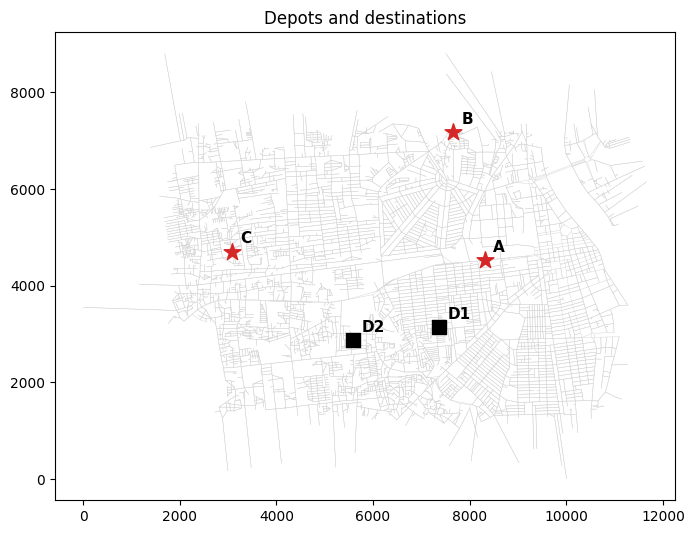

In [24]:
from matplotlib.collections import LineCollection

def plot_scenario(G, labels, van_routes=None, title="Depots and destinations"):
    """
    labels     : {"D1": node, "D2": node, "A": node, ...}
    van_routes : optional {"Van 1": [node, node, ...], "Van 2": [...]}  (full road paths)
    """
    fig, ax = plt.subplots(figsize=(8, 8))

    # road network (drawn as one collection, much faster than one plot per edge)
    segments = [(G.nodes[u]["pos"], G.nodes[v]["pos"]) for u, v in G.edges]
    ax.add_collection(LineCollection(segments, colors="lightgray", linewidths=0.3, zorder=1))

    # optional routes
    if van_routes:
        for (van_name, path), colour in zip(van_routes.items(), ["tab:blue", "tab:orange"]):
            xs, ys = zip(*(G.nodes[n]["pos"] for n in path))
            ax.plot(xs, ys, lw=2, color=colour, zorder=2, label=van_name)

    # depots and destinations
    for name, node in labels.items():
        x, y = G.nodes[node]["pos"]
        is_depot = name.startswith("D")
        ax.scatter(x, y, marker="s" if is_depot else "*",
                   s=100 if is_depot else 160,
                   c="black" if is_depot else "tab:red", zorder=3)
        ax.annotate(name, (x, y), xytext=(6, 6), textcoords="offset points",
                    fontsize=11, fontweight="bold")

    ax.autoscale()
    ax.set_aspect("equal")
    ax.set_title(title)
    if van_routes:
        ax.legend(loc="best")
    plt.show()

plot_scenario(G, labels)

In [25]:
from matplotlib.lines import Line2D

def van_legs(G, labels, van1_stops, van2_stops):
    """One entry per stop-to-stop leg: depot -> stop -> ... -> back to its own depot."""
    legs = []
    for van, depot, stops in [("Van 1", "D1", van1_stops), ("Van 2", "D2", van2_stops)]:
        seq = [depot] + list(stops) + [depot]
        for a, b in zip(seq, seq[1:]):
            if a == b:                      # idle van: nothing to draw
                continue
            path = nx.shortest_path(G, labels[a], labels[b], weight="weight")
            legs.append({"van": van, "from": a, "to": b, "path": path})
    return legs

In [26]:

import matplotlib.patheffects as pe

def plot_plan(G, labels, legs, d=None, title="Optimal plan from QUBO"):
    fig, ax = plt.subplots(figsize=(9, 9))

    segments = [(G.nodes[u]["pos"], G.nodes[v]["pos"]) for u, v in G.edges]
    ax.add_collection(LineCollection(segments, colors="lightgray", linewidths=0.3, zorder=1))

    palette = plt.get_cmap("tab10").colors
    legend_items = []
    n_legs = len(legs)
    for k, leg in enumerate(legs):
        colour = palette[k % len(palette)]
        xs, ys = zip(*(G.nodes[n]["pos"] for n in leg["path"]))
        # earlier legs thicker, later legs thinner on top, so shared roads show both colours
        lw = 2 + 3 * (n_legs - 1 - k) / max(n_legs - 1, 1)
        ax.plot(xs, ys, lw=lw, color=colour, zorder=2 + k * 0.01, solid_capstyle="round")

        # direction arrow near the middle of the leg
        mid = len(leg["path"]) // 2
        if mid > 0:
            (x0, y0) = G.nodes[leg["path"][mid - 1]]["pos"]
            (x1, y1) = G.nodes[leg["path"][mid]]["pos"]
            arrow = ax.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=4,
                    arrowprops=dict(arrowstyle="-|>", color=colour, lw=1, mutation_scale=12))

            arrow.arrow_patch.set_path_effects([
                pe.Stroke(linewidth=2, foreground="black"),
                pe.Normal()
            ])

        text = f'{leg["van"]}: {leg["from"]} \u2192 {leg["to"]}'
        if d is not None:
            text += f' ({d[(leg["from"], leg["to"])]:.0f} s)'
        legend_items.append(Line2D([0], [0], color=colour, lw=3, label=text))

    for name, node in labels.items():
        x, y = G.nodes[node]["pos"]
        is_depot = name.startswith("D")
        ax.scatter(x, y, marker="s" if is_depot else "*", s=110 if is_depot else 170,
                   c="black" if is_depot else "tab:red", zorder=5,
                   edgecolors="white", linewidths=0.8)
        ax.annotate(name, (x, y), xytext=(7, 7), textcoords="offset points",
                    fontsize=11, fontweight="bold", zorder=6)

    legend_items += [
        Line2D([0], [0], marker="s", color="w", markerfacecolor="black", markersize=9, label="Depot"),
        Line2D([0], [0], marker="*", color="w", markerfacecolor="tab:red", markersize=13, label="Destination"),
    ]
    ax.legend(handles=legend_items, loc="upper left", fontsize=8, framealpha=0.95)
    ax.autoscale(); ax.set_aspect("equal"); ax.set_title(title)
    plt.show()

Tour: ['D1', 'A', 'B', 'D2', 'C']
Van 1: ['A', 'B'] | Van 2: ['C']


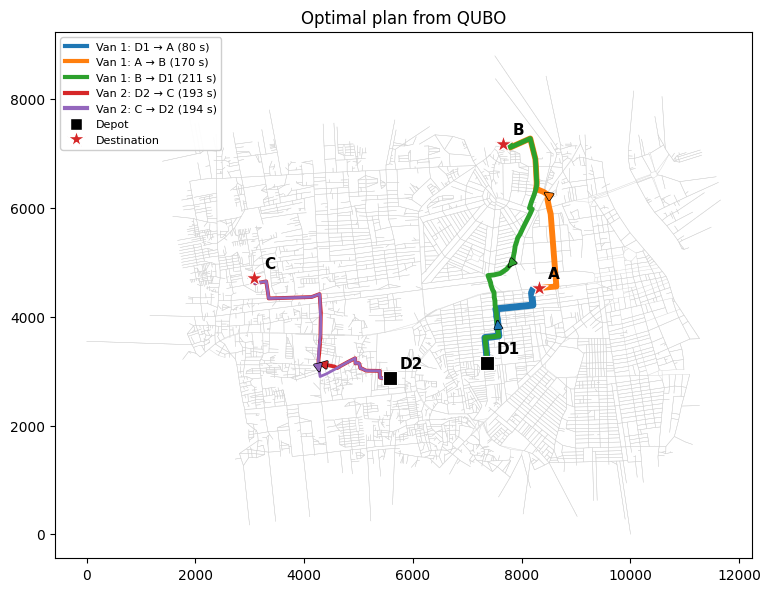

In [27]:
bits, energy = solve_exact(Q, variables)
tour, van1_stops, van2_stops = decode(bits, variables, dest_labels)
print("Tour:", tour)
print("Van 1:", van1_stops, "| Van 2:", van2_stops)

legs = van_legs(G, labels, van1_stops, van2_stops)
plot_plan(G, labels, legs, d=d)

## Next step

In [30]:
from src.fleetopt.two_depot import build_tour_qubo
Q, variables, A, offset= build_tour_qubo(d, dest_labels, A=None, B=1)

print(type(Q).__name__, "with", len(Q), "entries")
print("variables:", len(variables), "| A:", round(A, 4), "| offset:", round(offset, 4))
print("diagonal entries:    ", sum(a == b for a, b in Q))
print("off-diagonal entries:", sum(a != b for a, b in Q))

print("\nAll QUBO coefficients:")
for key, coefficient in Q.items():
    print(key, round(coefficient, 4))

dict with 100 entries
variables: 16 | A: 6372.2253 | offset: 796.5282
diagonal entries:     16
off-diagonal entries: 84

All QUBO coefficients:
(('D2', 1), ('D2', 1)) -1593.0563
(('D2', 2), ('D2', 2)) -1593.0563
(('D2', 3), ('D2', 3)) -1593.0563
(('D2', 4), ('D2', 4)) -1593.0563
(('D2', 1), ('D2', 2)) 1593.0563
(('D2', 1), ('D2', 3)) 1593.0563
(('D2', 1), ('D2', 4)) 1593.0563
(('D2', 2), ('D2', 3)) 1593.0563
(('D2', 2), ('D2', 4)) 1593.0563
(('D2', 3), ('D2', 4)) 1593.0563
(('A', 1), ('A', 1)) -1513.0887
(('A', 2), ('A', 2)) -1593.0563
(('A', 3), ('A', 3)) -1593.0563
(('A', 4), ('A', 4)) -1371.1901
(('A', 1), ('A', 2)) 1593.0563
(('A', 1), ('A', 3)) 1593.0563
(('A', 1), ('A', 4)) 1593.0563
(('A', 2), ('A', 3)) 1593.0563
(('A', 2), ('A', 4)) 1593.0563
(('A', 3), ('A', 4)) 1593.0563
(('B', 1), ('B', 1)) -1392.2924
(('B', 2), ('B', 2)) -1593.0563
(('B', 3), ('B', 3)) -1593.0563
(('B', 4), ('B', 4)) -1272.8406
(('B', 1), ('B', 2)) 1593.0563
(('B', 1), ('B', 3)) 1593.0563
(('B', 1), ('B', 4

In [ ]:

import numpy as np
import pandas as pd

# Create an empty 16 x 16 matrix
n = len(variables)
matrix = np.zeros((n, n))

# Map each QUBO coefficient to its matrix position
for (v1, v2), coefficient in Q.items():
    i = variables.index(v1)
    j = variables.index(v2)

    matrix[i, j] = coefficient

# Use variable names as row and column labels
labels = [f"{node}_{position}" for node, position in variables]

qubo_matrix = pd.DataFrame(
    matrix,
    index=labels,
    columns=labels
)

print(qubo_matrix.round(2))


         D2_1     D2_2     D2_3     D2_4      A_1      A_2      A_3      A_4  \
D2_1 -1593.06  1593.06  1593.06  1593.06  1593.06   193.11     0.00     0.00   
D2_2     0.00 -1593.06  1593.06  1593.06   112.55  1593.06   193.11     0.00   
D2_3     0.00     0.00 -1593.06  1593.06     0.00   112.55  1593.06   193.11   
D2_4     0.00     0.00     0.00 -1593.06     0.00     0.00   112.55  1593.06   
A_1      0.00     0.00     0.00     0.00 -1513.09  1593.06  1593.06  1593.06   
A_2      0.00     0.00     0.00     0.00     0.00 -1593.06  1593.06  1593.06   
A_3      0.00     0.00     0.00     0.00     0.00     0.00 -1593.06  1593.06   
A_4      0.00     0.00     0.00     0.00     0.00     0.00     0.00 -1371.19   
B_1      0.00     0.00     0.00     0.00     0.00     0.00     0.00     0.00   
B_2      0.00     0.00     0.00     0.00     0.00     0.00     0.00     0.00   
B_3      0.00     0.00     0.00     0.00     0.00     0.00     0.00     0.00   
B_4      0.00     0.00     0.00     0.00

### Ishing Hamiltonian

In [ ]:
def qubo_to_ising(Q, variables, offset):

    h = {v: 0.0 for v in variables}
    J = {}
    ising_offset = offset

    for (v1, v2), coefficient in Q.items():

        if v1 == v2:
            h[v1] -= coefficient / 2
            ising_offset += coefficient / 2

        else:
            J[(v1, v2)] = coefficient / 4

            h[v1] -= coefficient / 4
            h[v2] -= coefficient / 4

            ising_offset += coefficient / 4

    return h, J, ising_offset


### Cost function hamiltonian

In [ ]:

from qiskit.quantum_info import SparsePauliOp

def ising_to_cost_hamiltonian(h, J, ising_offset, variables):

    qubit_index = {
        variable: index
        for index, variable in enumerate(variables)
    }

    n = len(variables)
    pauli_terms = []

    # Constant term
    pauli_terms.append(("I" * n, ising_offset))

    # Individual spin terms
    for variable, coefficient in h.items():
        pauli = ["I"] * n
        pauli[n - 1 - qubit_index[variable]] = "Z"

        pauli_terms.append(("".join(pauli), coefficient))

    # Interaction terms
    for (v1, v2), coefficient in J.items():
        pauli = ["I"] * n

        pauli[n - 1 - qubit_index[v1]] = "Z"
        pauli[n - 1 - qubit_index[v2]] = "Z"

        pauli_terms.append(("".join(pauli), coefficient))

    return SparsePauliOp.from_list(pauli_terms)


In [ ]:
# 1. Build QUBO
Q, variables, A, offset = build_tour_qubo(
    d, dest_labels, A=A_cfg, B=B_cfg
)

# 2. Convert QUBO to Ising
h, J, ising_offset = qubo_to_ising(
    Q, variables, offset
)

# 3. Convert Ising to Cost Hamiltonian
cost_hamiltonian = ising_to_cost_hamiltonian(
    h, J, ising_offset, variables
)

# Print Ising model
print("\n========== ISING MODEL ==========")

print("\n--- Individual spin coefficients (h) ---")
for variable, coefficient in h.items():
    print(f"{str(variable):20} {coefficient:12.4f}")

print("\n--- Interaction coefficients (J) ---")
for (v1, v2), coefficient in J.items():
    print(f"{str(v1):12} <-> {str(v2):12} {coefficient:12.4f}")

print(f"\nIsing offset: {ising_offset:.4f}")


# 3. Convert Ising to Cost Hamiltonian
cost_hamiltonian = ising_to_cost_hamiltonian(
    h, J, ising_offset, variables
)

print("\n========== COST HAMILTONIAN ==========")

for pauli, coefficient in zip(
    cost_hamiltonian.paulis,
    cost_hamiltonian.coeffs
):
    print(f"{str(pauli):20} {coefficient.real:12.4f}")


========== ISING MODEL ==========

--- Individual spin coefficients (h) ---
('D2', 1)              -1768.1517
('D2', 2)              -1926.6550
('D2', 3)              -1926.6550
('D2', 4)              -1751.5597
('A', 1)               -1788.8675
('A', 2)               -1922.1347
('A', 3)               -1922.1347
('A', 4)               -1877.2404
('B', 1)               -1891.5434
('B', 2)               -1997.6762
('B', 3)               -1997.6762
('B', 4)               -1959.6790
('C', 1)               -1986.0728
('C', 2)               -2068.6441
('C', 3)               -2068.6441
('C', 4)               -1923.0161

--- Interaction coefficients (J) ---
('D2', 1)    <-> ('D2', 2)        398.2641
('D2', 1)    <-> ('D2', 3)        398.2641
('D2', 1)    <-> ('D2', 4)        398.2641
('D2', 2)    <-> ('D2', 3)        398.2641
('D2', 2)    <-> ('D2', 4)        398.2641
('D2', 3)    <-> ('D2', 4)        398.2641
('A', 1)     <-> ('A', 2)         398.2641
('A', 1)     <-> ('A', 3)         398.26